# Random forests for multilabel ECG classification

In this notebook, we will compare 60 ECG statistical features with the same 60 features + age and sex using random forest. This notebook uses the same waveform feature definition as the multilabel logistic
regression notebook and the shared diagnostic cohort and official folds used by
the CNN. Each experiment fits five independent binary random forests for
NORM, MI, STTC, CD, HYP; multiple diagnoses can be predicted for one ECG. I used Codex to write all the Python code in this notebook.

## 1. Load the shared data and extract 60 ECG features

Each 100 Hz, 10-second recording has 1,000 time points and 12 leads. Compute **mean,
population SD (`ddof=0`), minimum, maximum, and RMS** over time for each lead.
Concatenate in statistic-major order: 12 means, 12 SDs, 12 minima, 12 maxima,
12 RMS values. RMS is `sqrt(mean(voltage**2))`. All values are derived from the
original physical mV waveforms, not CNN-normalized inputs. No filtering, scaling,
PCA, or feature selection is added. Unlike the logistic notebook's indexing call,
this implementation indexes waveform rows *inside* each batch to avoid copying a
whole waveform partition. A regression test verifies exact numerical equivalence.

These summaries describe amplitude/variability rather than QRS duration or detailed
waveform morphology. They discard temporal ordering; RMS² = mean² + SD², so some
features are redundant. Record identifiers are used for alignment, never predictors.

In [ ]:
from pathlib import Path
import json
import os
import sys
import inspect
import time
import socket
from importlib.metadata import version

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Code, Markdown

%matplotlib inline

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "configs/preprocessing.yaml").is_file()), None)
if ROOT is None:
    raise FileNotFoundError("Run from inside the BIOS784 repository.")
if "longleaf-login" in socket.gethostname().lower() and not os.environ.get("SLURM_JOB_ID"):
    raise RuntimeError("Use a Longleaf CPU allocation for model fitting, not a login node.")
HERE = ROOT / "analysis/Thomas/Random_Forest"
sys.path.insert(0, str(HERE))
from rf_pipeline import (
    CLASSES, LEADS, DISPLAY_LEADS, FEATURE_NAMES, MODEL_NAMES, COLORS, SEARCH,
    load_data, choose_indices, extract_ecg_features, build_features,
    fit_demographics, clean_demographics, append_demographics, fit_trial, search_models,
    predict_forests, select_thresholds, evaluate, grouped_permutation_importance,
    impurity_importance, signature, read_json, save_json, plot_search,
    plot_performance, plot_importance, save_figure,
)
MODE = os.environ.get("RF_MODE", "smoke")
if MODE not in {"smoke", "full"}:
    raise ValueError("RF_MODE must be smoke or full.")
SMOKE = MODE == "smoke"
RUN_NAME = os.environ.get("RF_RUN_NAME", MODE)
if Path(RUN_NAME).name != RUN_NAME or RUN_NAME in {".", ".."}:
    raise ValueError("RF_RUN_NAME must be one directory name.")
SEED = 784
CORES = int(os.environ.get("SLURM_CPUS_PER_TASK", os.environ.get("RF_N_JOBS", "4")))
OUTPUT = HERE / "results" / RUN_NAME
FIGURES = OUTPUT / "figures"
OUTPUT.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(exist_ok=True)
started = time.perf_counter()
plt.rcParams.update({"axes.titlesize": 10, "axes.labelsize": 9, "font.size": 9})
environment = {p: version(p) for p in ["numpy", "pandas", "scikit-learn", "joblib", "matplotlib", "nbclient", "nbformat"]}
environment.update(mode=MODE, seed=SEED, CPUs=CORES, slurm_job_id=os.environ.get("SLURM_JOB_ID"))
save_json(OUTPUT / "environment.json", environment)
print("SMOKE VALIDATION ONLY; no held-out test outcomes are evaluated." if SMOKE else "FULL EXPERIMENT: held-out test follows validation selection.")
print(f"CPU cores: {CORES}; no GPU libraries or GPU allocation are required.")
display(pd.Series(environment, name="Environment").to_frame())

FULL EXPERIMENT: held-out test follows validation selection.
CPU cores: 8; no GPU libraries or GPU allocation are required.


,Environment
numpy,1.26.4
pandas,2.1.4
scikit-learn,1.2.2
joblib,1.2.0
matplotlib,3.8.0
nbclient,0.8.0
nbformat,5.9.2
mode,full
seed,784
CPUs,8


In [ ]:
data = load_data(ROOT)
indices = choose_indices(data, smoke=SMOKE, seed=SEED)
features = build_features(data, indices, OUTPUT)
# These caches contain private linkage and are excluded from Git.
np.savez_compressed(OUTPUT / "cohort_indices.npz", **indices)
save_json(OUTPUT / "data_provenance.json", data["provenance"])
feature_dictionary = pd.DataFrame({"feature": FEATURE_NAMES,
    "statistic": np.repeat(["Mean", "Std", "Min", "Max", "RMS"], 12),
    "lead": DISPLAY_LEADS * 5, "units": "mV"})
feature_dictionary.to_csv(OUTPUT / "feature_dictionary.csv", index=False)
display(Code(inspect.getsource(extract_ecg_features), language="python"))
summary_rows = []
prevalence_rows = []
for partition, rows in indices.items():
    summary_rows.append({"partition": partition, "ECGs": len(rows),
                         "patients": data["splits"].iloc[rows].patient_id.nunique(),
                         "ECG_features": features[partition].shape[1]})
    for j, label in enumerate(CLASSES):
        prevalence_rows.append({"partition": partition, "class": label,
            "positive": int(data["y"][rows, j].sum()),
            "prevalence": float(data["y"][rows, j].mean())})
cohort_summary = pd.DataFrame(summary_rows)
prevalence = pd.DataFrame(prevalence_rows)
cohort_summary.to_csv(OUTPUT / "cohort_summary.csv", index=False)
prevalence.to_csv(OUTPUT / "class_prevalence.csv", index=False)
display(cohort_summary)
display(prevalence.round(4))
print(f"Shared diagnostic eligibility excludes {(~data['eligible']).sum():,} all-zero-label ECGs from both models.")
print("Original patient-disjoint fold assignments and recording alignment verified.")

def extract_ecg_features(waveforms, indices, batch_size=256):
    """Exact five-statistic, statistic-major representation from Shreya's LR notebook.

    Index within batches, so advanced indexing never copies an entire split.
    """
    indices = np.asarray(indices)
    features = np.empty((len(indices), 60), dtype=np.float32)
    for start in range(0, len(indices), batch_size):
        rows = indices[start:start + batch_size]
        batch = np.asarray(waveforms[rows], dtype=np.float32)
        if batch.shape != (len(rows), 1000, 12) or not np.isfinite(batch).all():
            raise ValueError('Invalid/nonfinite ECG waveform.')
        values = np.concatenate([batch.mean(axis=1), batch.std(axis=1), batch.min(axis=1),
                                 batch.max(axis=1), np.sqrt(np.mean(batch**2, axis=1))], axis=1)
        if not np.isfinite(values).all():
            raise ValueError('Invalid ECG features.')
        features[start:start + len(rows)] = values
    return features

,partition,ECGs,patients,ECG_features
0,train,17084,14823,60
1,validation,2146,1917,60
2,test,2158,1877,60


,partition,class,positive,prevalence
0,train,NORM,7596,0.4446
1,train,MI,4379,0.2563
2,train,STTC,4186,0.2450
3,train,CD,3907,0.2287
4,train,HYP,2119,0.1240
5,validation,NORM,955,0.4450
6,validation,MI,540,0.2516
7,validation,STTC,528,0.2460
8,validation,CD,495,0.2307
9,validation,HYP,268,0.1249


Shared diagnostic eligibility excludes 411 all-zero-label ECGs from both models.
Original patient-disjoint fold assignments and recording alignment verified.


## 2. Age and sex and the two predictor sets

For the combined model, append age and sex to produce **62 predictors**. Age is
missing if absent, nonfinite, negative, above 89, or flagged as deidentified.
Impute with the **training median**. Sex is 0 male / 1 female; invalid/missing
values use the training mode. No records are excluded for demographics, so both
models use the exact same cohort. All imputation parameters are fitted on training
only. Tree models do not require feature standardization; age stays in years.

Height, weight, IDs, diagnostic text/codes, and annotation fields are not predictors.
The source processed files are not modified.

In [ ]:
demographic_parameters = fit_demographics(data, indices["train"])
combined_features = append_demographics(data, indices, features, demographic_parameters)
experiments = {MODEL_NAMES[0]: features, MODEL_NAMES[1]: combined_features}
save_json(OUTPUT / "demographic_preprocessing.json", demographic_parameters)
display(pd.Series(demographic_parameters, name="Training-only imputation").to_frame())
demographic_rows = []
raw = clean_demographics(data["predictors"])
for partition, rows in indices.items():
    demographic_rows.append({"partition": partition,
        "age_missing_or_deidentified": int(np.isnan(raw[rows, 0]).sum()),
        "observed_age_mean": float(np.nanmean(raw[rows, 0])),
        "observed_age_SD": float(np.nanstd(raw[rows, 0], ddof=1)),
        "sex_missing_or_invalid": int(np.isnan(raw[rows, 1]).sum()),
        "female_percent_observed": float(np.nanmean(raw[rows, 1]) * 100)})
demographic_summary = pd.DataFrame(demographic_rows)
demographic_summary.to_csv(OUTPUT / "demographic_summary.csv", index=False)
display(demographic_summary.round(2))
assert all(x.shape[1] == 60 for x in features.values())
assert all(x.shape[1] == 62 for x in combined_features.values())

,Training-only imputation
age_median,61.0
sex_mode,0.0
fitted_partition,train
training_ids_hash,e98b33296b92b280ae84fdf39e4ed41d1d822476f30cce...
age_policy,"Source age <0, >89, missing, or deidentified -..."
sex_policy,0 male / 1 female; invalid/missing -> training...
scaling,none; tree inputs do not need scaling


,partition,age_missing_or_deidentified,observed_age_mean,observed_age_SD,sex_missing_or_invalid,female_percent_observed
0,train,212,59.24,16.67,0,47.98
1,validation,41,59.65,17.12,0,48.09
2,test,32,60.42,17.33,0,48.56


## 3. Fit and tune five binary random forests per experiment

Each trial fits five separate scikit-learn `RandomForestClassifier` models. The
labels and trials run sequentially; trees within one forest use the allocated CPU
cores, preventing nested oversubscription. Bootstrap sampling and seed 784 are fixed.

The same **four prespecified candidates** are offered to both experiments. Each
uses 200 trees per diagnosis; depth, minimum leaf size, feature sampling, and optional
`balanced_subsample` class weighting vary. Class weights depend only on training
bootstrap samples. Select the trial with the highest **validation macro-AUROC**;
ties retain the earlier trial. Do not retrain on train + validation afterward.
RFs do not have neural-network epochs or loss curves; the plots show validation
scores and measured fit time for each trial instead.

,n_estimators,max_depth,min_samples_leaf,max_features,class_weight
full_search_trial,,,,,
0,200,NaN,1,sqrt,None
1,200,20.0,3,sqrt,balanced_subsample
2,200,NaN,3,0.5,balanced_subsample
3,200,20.0,5,sqrt,None


def fit_trial(x_train, y_train, x_val, y_val, config, folder, identity, cores=4, seed=784):
    """Five independent binary forests; parallelize trees, not labels or trials."""
    check_classes(y_train)
    check_classes(y_val)
    folder = Path(folder)
    folder.mkdir(parents=True, exist_ok=True)
    fingerprint = signature(dict(identity=identity, config=config, seed=seed, n_features=x_train.shape[1],
        matrices={name: hashlib.sha256(np.ascontiguousarray(values).tobytes()).hexdigest()
                  for name, values in [('train_x', x_train), ('train_y', y_train), ('validation_x', x_val), ('validation_y', y_val)]}))
    status_path = folder / 'status.json'
    previous = read_json(status_path) if status_path.exists() else None
    if previous and previous['signature'] != fingerprint:
        raise ValueError('Model cache is stale; choose a new RF_RUN_NAME.')
    forests, class_history = {}, []
    try:
        for j, label in enumerate(CLASSES):
            path = folder / f'{label}.joblib'
            if path.exists():
                saved = joblib.load(path)  # Trusted, locally generated analysis artifacts only.
                if saved['signature'] != fingerprint:
                    raise ValueError('Saved estimator signature mismatch.')
                forest, elapsed = saved['forest'], saved['fit_seconds']
                forest.n_jobs = cores
            else:
                forest = RandomForestClassifier(**config, n_jobs=cores, random_state=seed,
                                                criterion='gini', bootstrap=True)
                start = time.perf_counter()
                forest.fit(x_train, y_train[:, j])
                elapsed = time.perf_counter() - start
                temporary = path.with_suffix('.tmp')
                joblib.dump(dict(signature=fingerprint, forest=forest, fit_seconds=elapsed), temporary, compress=3)
                temporary.replace(path)
            forests[label] = forest
            class_history.append(dict(class_name=label, trees=len(forest.estimators_), fit_seconds=elapsed))
            save_json(status_path, dict(signature=fingerprint, status='training', completed_classes=len(forests),
                                        config=config, class_history=class_history))
        p = predict_forests(forests, x_val)
        auc = float(roc_auc_score(y_val, p, average='macro'))
        save_json(status_path, dict(signature=fingerprint, status='completed', completed_classes=5,
                                    validation_macro_AUROC=auc, config=config, class_history=class_history))
        return forests, p, dict(signature=fingerprint, validation_macro_AUROC=auc,
                                fit_seconds=sum(c['fit_seconds'] for c in class_history), config=config)
    except BaseException as exc:
        save_json(status_path, dict(signature=fingerprint, status='interrupted' if isinstance(exc, KeyboardInterrupt) else 'failed',
                                    completed_classes=len(forests), error=type(exc).__name__, config=config))
        raise

ECG only, trial 0: validation macro-AUROC 0.8196


ECG only, trial 1: validation macro-AUROC 0.8245


ECG only, trial 2: validation macro-AUROC 0.8236


ECG only, trial 3: validation macro-AUROC 0.8257


... (2 outputs left out)

ECG + demographics, trial 2: validation macro-AUROC 0.8384


ECG + demographics, trial 3: validation macro-AUROC 0.8393


,model,trial,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,validation_macro_AUROC,fit_seconds,status
0,ECG only,0,200,NaN,1,sqrt,None,0.8196,20.8332,completed
1,ECG only,1,200,20.0,3,sqrt,balanced_subsample,0.8245,19.0019,completed
2,ECG only,2,200,NaN,3,0.5,balanced_subsample,0.8236,67.3641,completed
3,ECG only,3,200,20.0,5,sqrt,None,0.8257,16.7863,completed
4,ECG + demographics,0,200,NaN,1,sqrt,None,0.8344,18.5907,completed
5,ECG + demographics,1,200,20.0,3,sqrt,balanced_subsample,0.8393,16.3558,completed
6,ECG + demographics,2,200,NaN,3,0.5,balanced_subsample,0.8384,61.4809,completed
7,ECG + demographics,3,200,20.0,5,sqrt,None,0.8393,14.6241,completed


,model,selected_trial,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,validation_macro_AUROC
0,ECG only,3,200,20,5,sqrt,None,0.8257
1,ECG + demographics,1,200,20,3,sqrt,balanced_subsample,0.8393


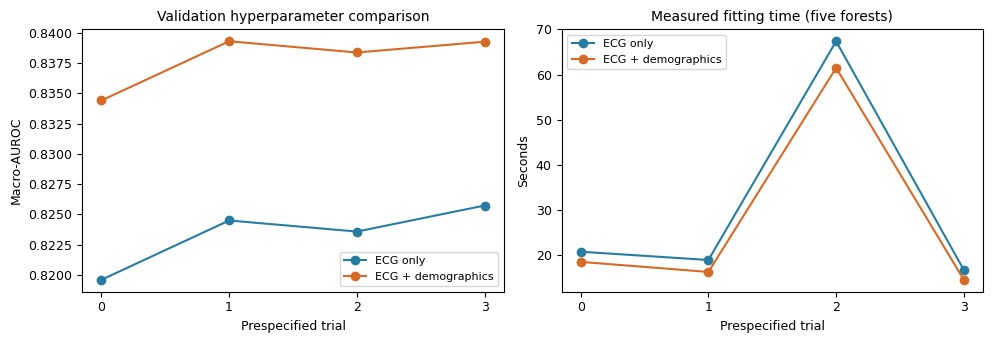

In [ ]:
display(pd.DataFrame(SEARCH).rename_axis("full_search_trial"))
display(Code(inspect.getsource(fit_trial), language="python"))
models, selected, validation_predictions, search_table = search_models(
    data, indices, experiments, demographic_parameters, OUTPUT,
    smoke=SMOKE, cores=CORES, seed=SEED)
display(search_table.round(4))
selected_table = pd.DataFrame([{"model": name, "selected_trial": result["trial"], **result["config"],
    "validation_macro_AUROC": result["validation_macro_AUROC"]} for name, result in selected.items()])
selected_table.to_csv(OUTPUT / "selected_configurations.csv", index=False)
display(selected_table.round(4))
plot_search(search_table, FIGURES)
plt.show()

## 4. Evaluate the finalized models

Select each class's probability threshold using **validation F1**, with `p >= t`
and largest-threshold tie-breaking, then freeze trial choices and thresholds
before test evaluation. Macro metrics are unweighted means over the five classes.
AUROC and average precision use probabilities; **macro-AUPRC means macro average
precision (AP)**, not trapezoidal integration. Also report macro-F1 at 0.5 so it can
be compared with the logistic notebook's fixed-threshold F1. The validation-selected
F1 convention matches the CNN. No class can silently drop out of the macro average.

,ECG only,ECG + demographics
Validation-selected thresholds,,
NORM,0.400083,0.375756
MI,0.310539,0.334036
STTC,0.250765,0.339219
CD,0.350224,0.431848
HYP,0.312761,0.363840


**Held-out test. Macro-AUPRC uses the AP convention.**

,model,assessment,macro_AUROC,macro_F1,macro_AUPRC_AP,macro_F1_at_0_5
0,ECG only,Held-out test,0.8091,0.5974,0.6340,0.4947
1,ECG + demographics,Held-out test,0.8235,0.6023,0.6457,0.5516


,class_name,AUROC,average_precision,F1,precision,recall,threshold,model
0,NORM,0.8159,0.7618,0.7299,0.6386,0.8515,0.4001,ECG only
1,MI,0.8047,0.6097,0.5691,0.5171,0.6327,0.3105,ECG only
2,STTC,0.7423,0.5048,0.5067,0.4007,0.6891,0.2508,ECG only
3,CD,0.8249,0.7020,0.6223,0.6430,0.6028,0.3502,ECG only
4,HYP,0.8578,0.5915,0.5591,0.5498,0.5687,0.3128,ECG only
5,NORM,0.8459,0.8019,0.7549,0.6533,0.8941,0.3758,ECG + demographics
6,MI,0.8157,0.6154,0.5773,0.4851,0.7127,0.3340,ECG + demographics
7,STTC,0.7654,0.5176,0.5188,0.4440,0.6238,0.3392,ECG + demographics
8,CD,0.8284,0.6958,0.6137,0.6667,0.5685,0.4318,ECG + demographics
9,HYP,0.8620,0.5979,0.5468,0.5170,0.5802,0.3638,ECG + demographics


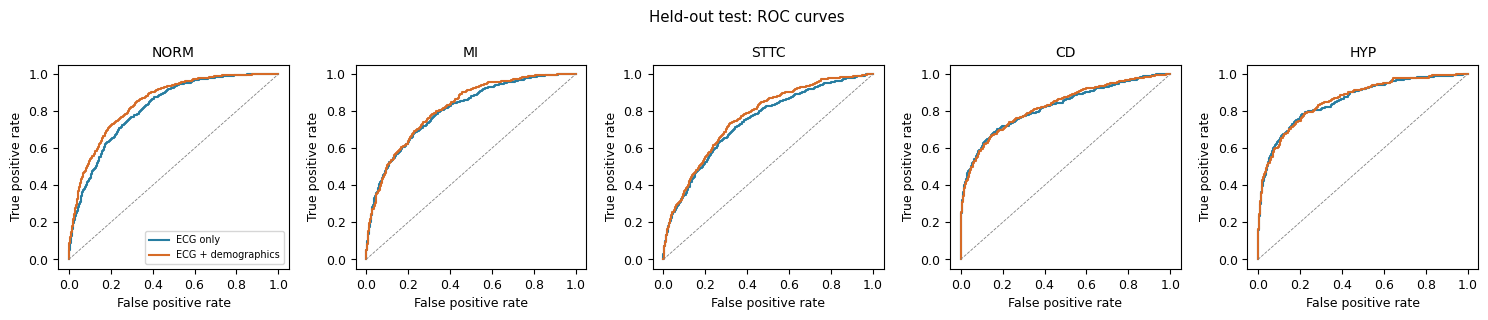

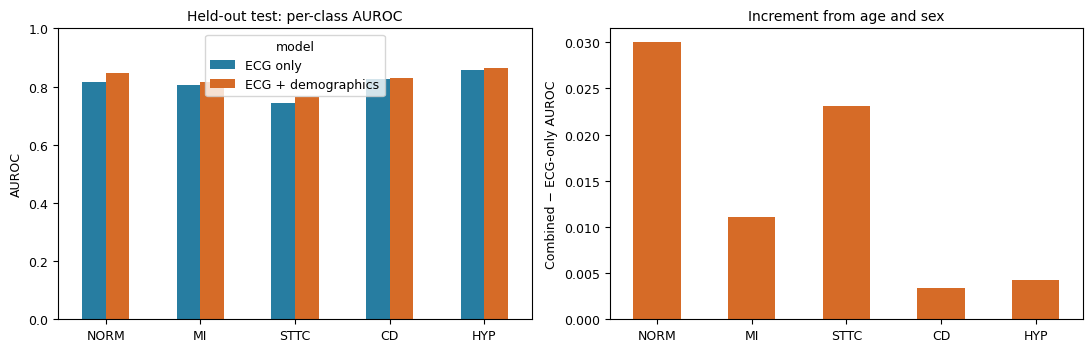

In [ ]:
thresholds = {name: select_thresholds(data["y"][indices["validation"]], p)
              for name, p in validation_predictions.items()}
frozen = {"selection_source": "validation", "threshold_source": "validation", "test_used_for_selection": False,
    "cohort_hash": data["provenance"]["cohort_hash"],
    "model_signatures": {name: result["signature"] for name, result in selected.items()},
    "selected_trials": {name: result["trial"] for name, result in selected.items()},
    "thresholds": {name: t.tolist() for name, t in thresholds.items()}}
# Reuse already-frozen thresholds on cached reruns. Parallel forest inference
# can differ at floating-point roundoff; it must not revise a completed selection.
frozen_path = OUTPUT / "selection_frozen.json"
if frozen_path.exists():
    saved_selection = read_json(frozen_path)
    assert {k: v for k, v in frozen.items() if k != "thresholds"} == {
        k: v for k, v in saved_selection.items() if k != "thresholds"
    }, "Selection changed; use a new RF_RUN_NAME."
    frozen = saved_selection
    thresholds = {name: np.asarray(values) for name, values in frozen["thresholds"].items()}
else:
    save_json(frozen_path, frozen)
display(pd.DataFrame(thresholds, index=CLASSES).rename_axis("Validation-selected thresholds"))
partition = "validation" if SMOKE else "test"
assessment = "Smoke validation (not final)" if SMOKE else "Held-out test"
evaluation_rows = indices[partition]
y_evaluation = data["y"][evaluation_rows]
overall_rows, per_class_tables, probabilities = [], [], {}
for number, name in enumerate(MODEL_NAMES):
    path = OUTPUT / f"predictions_{partition}_{number}.npz"
    cache_signature = signature({"selection": frozen, "partition": partition})
    if path.exists():
        with np.load(path, allow_pickle=False) as saved:
            assert str(saved["signature"].item()) == cache_signature
            assert np.array_equal(saved["recording_ids"], data["ids"][evaluation_rows])
            assert np.array_equal(saved["targets"], y_evaluation)
            p = saved["probabilities"]
    else:
        p = validation_predictions[name] if SMOKE else predict_forests(models[name], experiments[name][partition])
        np.savez_compressed(path, signature=cache_signature, recording_ids=data["ids"][evaluation_rows],
                            targets=y_evaluation, probabilities=p)
    probabilities[name] = p
    overall, per_class = evaluate(y_evaluation, p, thresholds[name])
    overall_rows.append({"model": name, "assessment": assessment, **overall})
    per_class["model"] = name
    per_class_tables.append(per_class)
overall_performance = pd.DataFrame(overall_rows)
per_class_performance = pd.concat(per_class_tables, ignore_index=True)
overall_performance.to_csv(OUTPUT / f"{partition}_overall_performance.csv", index=False)
per_class_performance.to_csv(OUTPUT / f"{partition}_per_class_performance.csv", index=False)
display(Markdown(f"**{assessment}. Macro-AUPRC uses the AP convention.**"))
display(overall_performance.round(4))
display(per_class_performance.round(4))
plot_performance(y_evaluation, probabilities, per_class_performance, FIGURES, assessment)
plt.show()

## 5. Incremental value of age and sex

Differences are **combined minus ECG only**, with identical recordings and splits.
Positive values favor the combined model for that metric. These point estimates
are not statistical tests, causal effects, or claims about external populations.

In [ ]:
metric_names = ["macro_AUROC", "macro_F1", "macro_AUPRC_AP", "macro_F1_at_0_5"]
metric_table = overall_performance.set_index("model")[metric_names]
increment = (metric_table.loc[MODEL_NAMES[1]] - metric_table.loc[MODEL_NAMES[0]]).rename("combined_minus_ECG_only")
class_auc = per_class_performance.pivot(index="class_name", columns="model", values="AUROC").reindex(CLASSES)
class_increment = (class_auc[MODEL_NAMES[1]] - class_auc[MODEL_NAMES[0]]).rename("AUROC_change")
increment.to_csv(OUTPUT / f"{partition}_incremental_macro_metrics.csv")
class_increment.to_csv(OUTPUT / f"{partition}_incremental_class_AUROC.csv")
display(increment.to_frame().round(4))
display(class_increment.to_frame().round(4))

,combined_minus_ECG_only
macro_AUROC,0.0144
macro_F1,0.0049
macro_AUPRC_AP,0.0117
macro_F1_at_0_5,0.0569


,AUROC_change
class_name,
NORM,0.0300
MI,0.0110
STTC,0.0231
CD,0.0034
HYP,0.0042


## 6. Feature and lead importance

The first plot shows training impurity importance averaged across the five binary
forests. Correlation, redundancy, and numbers of possible splits can affect those
rankings; they are not effect sizes or clinical significance tests.

For **validation-only permutation importance**, shuffle a lead's **five summary
features together**, using the same donor recording for all five. This preserves
within-lead relationships such as RMS² = mean² + SD². Age and sex are shuffled
individually. Corresponding lead permutations are identical between experiments.
Full mode uses five repeats; smoke uses two. Report the drop in validation
macro-AUROC, retaining negative values. Error bars show repeat SD, not confidence
intervals. Other leads/demographics may be correlated, and the procedure is
recording-level, not a patient bootstrap. Importance is descriptive and is not
used for feature selection or further test-driven tuning.

,model,feature,importance
0,ECG only,Min_aVR,0.035114
1,ECG only,Max_V5,0.032283
2,ECG only,Min_III,0.027786
3,ECG only,Std_V1,0.027612
4,ECG only,Max_II,0.026412
5,ECG only,RMS_V1,0.025662
6,ECG only,Min_V1,0.025579
7,ECG only,Max_V4,0.024300
8,ECG only,Min_aVF,0.023591
9,ECG only,RMS_V5,0.023458


,model,feature,importance
0,ECG + demographics,Age,0.047725
1,ECG + demographics,Min_aVR,0.030835
2,ECG + demographics,RMS_V1,0.026258
3,ECG + demographics,Min_III,0.025951
4,ECG + demographics,Max_V5,0.025646
5,ECG + demographics,Std_V1,0.024514
6,ECG + demographics,Max_II,0.022600
7,ECG + demographics,Min_V1,0.022256
8,ECG + demographics,Std_V5,0.021124
9,ECG + demographics,Min_aVF,0.020503


,model,kind,feature,mean,std
0,ECG + demographics,demographic,Age,0.0323,0.0030
1,ECG + demographics,demographic,Sex,0.0010,0.0003
2,ECG + demographics,lead,I,0.0041,0.0006
3,ECG + demographics,lead,II,0.0099,0.0012
4,ECG + demographics,lead,III,0.0071,0.0008
5,ECG + demographics,lead,V1,0.0222,0.0027
6,ECG + demographics,lead,V2,0.0071,0.0009
7,ECG + demographics,lead,V3,0.0073,0.0009
8,ECG + demographics,lead,V4,0.0076,0.0008
9,ECG + demographics,lead,V5,0.0159,0.0009


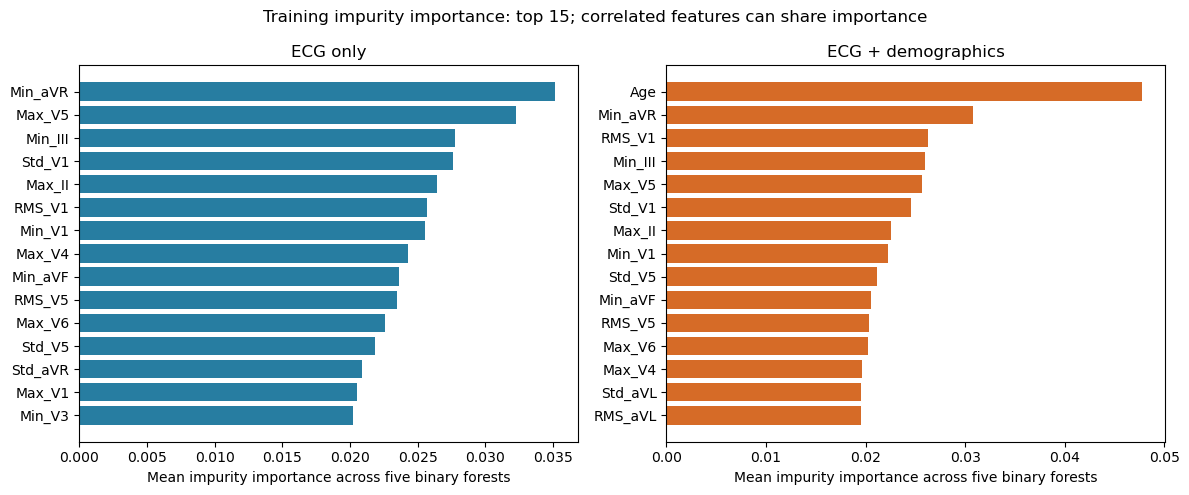

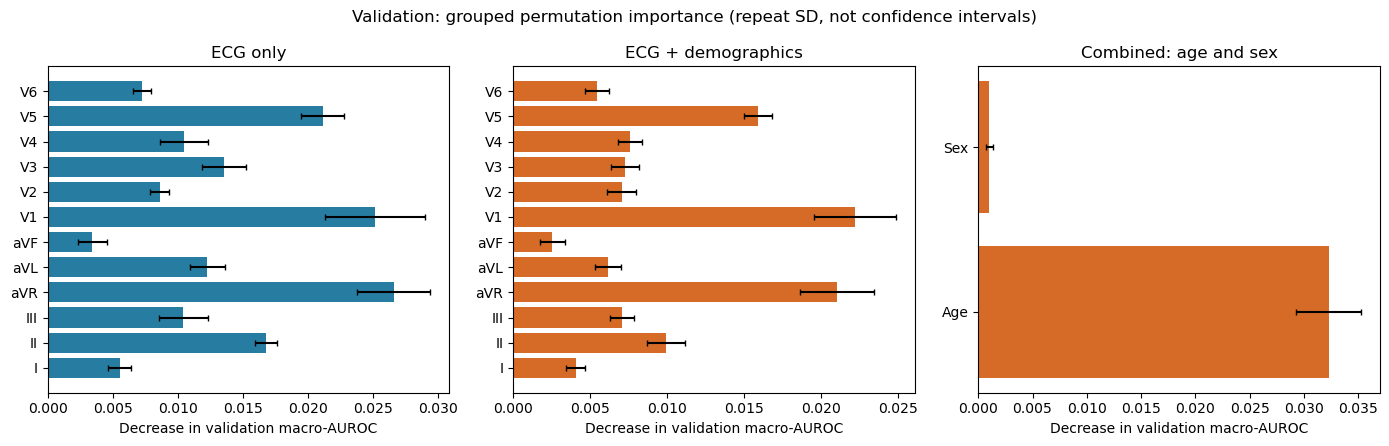

In [ ]:
impurity = impurity_importance(models)
impurity.to_csv(OUTPUT / "per_class_impurity_importance.csv", index=False)
mean_impurity = impurity.groupby(["model", "feature"]).importance.mean().reset_index()
mean_impurity.to_csv(OUTPUT / "mean_impurity_importance.csv", index=False)
for name in MODEL_NAMES:
    display(mean_impurity.loc[mean_impurity.model == name].nlargest(15, "importance").reset_index(drop=True))
importance_tables = []
repeats = 2 if SMOKE else 5
for number, name in enumerate(MODEL_NAMES):
    cache = OUTPUT / f"permutation_{number}.csv"
    meta = cache.with_suffix(".json")
    identity = signature({"selection": frozen, "repeats": repeats, "seed": SEED,
                          "validation_ids": data["ids"][indices["validation"]].tolist()})
    if cache.exists() and meta.exists():
        assert read_json(meta)["signature"] == identity
        table = pd.read_csv(cache)
    else:
        table = grouped_permutation_importance(models[name], experiments[name]["validation"],
            data["y"][indices["validation"]], demographics=name == MODEL_NAMES[1], repeats=repeats, seed=SEED)
        table.to_csv(cache, index=False)
        save_json(meta, {"signature": identity, "partition": "validation"})
    table["model"] = name
    importance_tables.append(table)
importance_all = pd.concat(importance_tables, ignore_index=True)
importance_all.to_csv(OUTPUT / "permutation_importance_repeats.csv", index=False)
_, _, importance_summary = plot_importance(impurity, importance_all, FIGURES, "Smoke validation" if SMOKE else "Validation")
importance_summary.to_csv(OUTPUT / "permutation_importance_summary.csv", index=False)
display(importance_summary.round(4))
plt.show()
assert len(importance_all) == (12 + 14) * repeats
assert np.isfinite(importance_all.decrease_macro_AUROC).all()